In [6]:
import os

print(os.listdir(r"C:\Users\ADMIN\Downloads\archive"))

['insurance.csv']


In [7]:
df = pd.read_csv(r"C:\Users\ADMIN\Downloads\archive\insurance.csv")

In [8]:
import os

print(os.listdir(r"C:\Users\ADMIN\Downloads\archive"))

['insurance.csv']


In [9]:
df = pd.read_csv(r"C:\Users\ADMIN\Downloads\archive\insurance.csv")

In [11]:
import pandas as pd

df = pd.read_csv(r"C:\Users\ADMIN\Downloads\archive\insurance.csv")

print("Dataset Loaded Successfully!")
print(df.head())

Dataset Loaded Successfully!
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [13]:

import pandas as pd
df = pd.read_csv(r"C:\Users\ADMIN\Downloads\archive\insurance.csv")
print("First 5 Rows:")
print(df.head())
print("\nNumber of Rows and Columns:")
print(df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

First 5 Rows:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

Number of Rows and Columns:
(1338, 7)

Column Names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [15]:

X = df.drop("charges", axis=1)
Y = df["charges"]
print("Input Features (X):")
print(X.head())
print("\nTarget Variable (Y):")
print(Y.head())
print("\nX Shape:", X.shape)
print("Y Shape:", Y.shape)


Input Features (X):
   age     sex     bmi  children smoker     region
0   19  female  27.900         0    yes  southwest
1   18    male  33.770         1     no  southeast
2   28    male  33.000         3     no  southeast
3   33    male  22.705         0     no  northwest
4   32    male  28.880         0     no  northwest

Target Variable (Y):
0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

X Shape: (1338, 6)
Y Shape: (1338,)


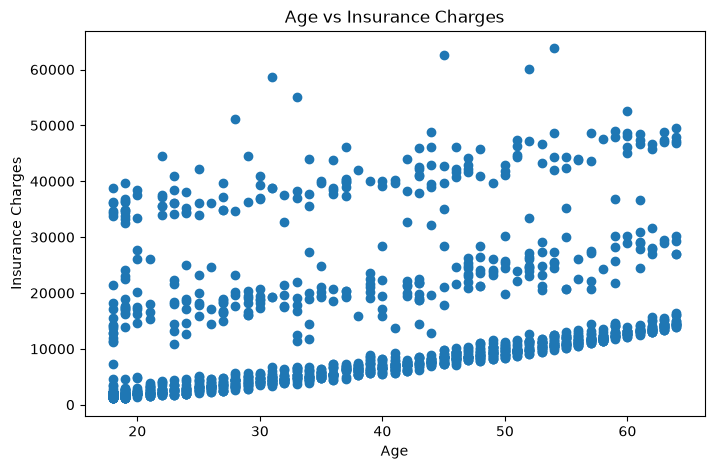

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.scatter(df["age"], df["charges"])
plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)
print("Training Data:")
print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("\nTesting Data:")
print("X_test:", X_test.shape)
print("Y_test:", Y_test.shape)

Training Data:
X_train: (1070, 6)
Y_train: (1070,)

Testing Data:
X_test: (268, 6)
Y_test: (268,)


In [19]:
from sklearn.linear_model import LinearRegression
X = pd.get_dummies(df.drop("charges", axis=1), drop_first=True)
Y = df["charges"]
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)
model = LinearRegression()
model.fit(X_train, Y_train)
print("Model Trained Successfully!")

Model Trained Successfully!


In [20]:

Y_pred = model.predict(X_test)
result = pd.DataFrame({
    "Actual Charges": Y_test.values,
    "Predicted Charges": Y_pred
})

print("Actual vs Predicted Insurance Charges:")
print(result.head(10))

Actual vs Predicted Insurance Charges:
   Actual Charges  Predicted Charges
0      9095.06825        8969.550274
1      5272.17580        7068.747443
2     29330.98315       36858.410912
3      9301.89355        9454.678501
4     33750.29180       26973.173457
5      4536.25900       10864.113164
6      2117.33885         170.280841
7     14210.53595       16903.450287
8      3732.62510        1092.430936
9     10264.44210       11218.343184


In [21]:
from sklearn.metrics import mean_absolute_error, r2_score
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)
print("Mean Absolute Error (MAE):", mae)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 4181.1944737536505
R2 Score: 0.7835929767120724
